# 1. Fitting Lines and Curves

Practice for the boundary-detection module: vertical least squares (with the quiz example), polynomial
fitting with the pseudo-inverse, total least squares for steep lines, and an active contour (snake) that
shrinks onto an object boundary using elasticity, smoothness and image terms.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 1.1 Vertical least squares

Minimize `E = 1/N Σ (y_i − m x_i − c)²`: `m = Sxy / Sxx`, `c = ȳ − m x̄`.

In [2]:
def fit_line(x, y):
    xm, ym = x.mean(), y.mean()
    m = ((x - xm) * (y - ym)).sum() / ((x - xm) ** 2).sum()
    return m, ym - m * xm

x = np.array([1, 2, 4, 5.0]); y = np.array([1, 1, 3, 3.0])
print("Sxy =", ((x - 3) * (y - 2)).sum(), "Sxx =", ((x - 3) ** 2).sum(), "-> m, c =", tuple(round(float(v), 4) for v in fit_line(x, y)))

Sxy = 6.0 Sxx = 10.0 -> m, c = (0.6, 0.2)


## 1.2 Polynomials and the pseudo-inverse

`y = a x² + b x + c` is non-linear in x but linear in (a, b, c), so each point gives one row of `A p = y`
and `p = (AᵀA)⁻¹ Aᵀ y`.

(a, b, c) = [-1.  4. -2.]
AᵀA =
 [[110.  40.]
 [ 40.  26.]]
A⁺ (as fractions): [['-3/35', '19/210', '1/14'], ['2/7', '-1/42', '-1/14']]
matches np.linalg.pinv: True


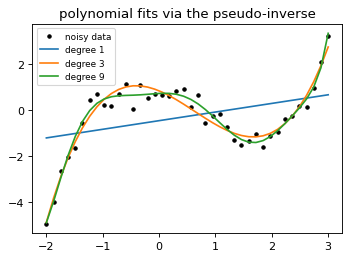

In [3]:
xs = np.array([1, 2, 3.0]); ys = np.array([1, 2, 1.0])
A = np.c_[xs ** 2, xs, np.ones(3)]
print("(a, b, c) =", np.linalg.inv(A.T @ A) @ A.T @ ys)

M = np.array([[2, 4], [9, 3], [5, 1]], float)
P = np.linalg.inv(M.T @ M) @ M.T
print("AᵀA =\n", M.T @ M)
print("A⁺ (as fractions):", [[str(Fraction(v).limit_denominator(1000)) for v in row] for row in P])
print("matches np.linalg.pinv:", np.allclose(P, np.linalg.pinv(M)))

xn = np.linspace(-2, 3, 40); yn = 0.5 * xn ** 3 - xn ** 2 - xn + 1 + rng.normal(0, 0.5, 40)
plt.figure(figsize=(5, 3.4)); plt.plot(xn, yn, "k.", label="noisy data")
for deg in [1, 3, 9]:
    p = np.linalg.pinv(np.vander(xn, deg + 1)) @ yn
    plt.plot(xn, np.vander(xn, deg + 1) @ p, label=f"degree {deg}")
plt.legend(fontsize=8); plt.title("polynomial fits via the pseudo-inverse"); plt.show()

## 1.3 Total least squares

Vertical least squares measures error along y and breaks down for steep lines (vertical lines are impossible
as `y = mx + c`). Total least squares uses the line `x sin θ − y cos θ + ρ = 0` and minimizes perpendicular
distances. Setting `∂E/∂ρ = 0` gives `ρ = −(x̄ sin θ − ȳ cos θ)`, i.e. the line passes through the centroid;
θ comes from the smallest eigenvector of the scatter matrix.

mean perpendicular distance: vertical LS 0.0344, total LS 0.0221


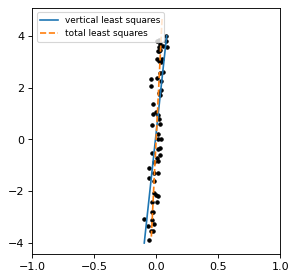

In [4]:
t = rng.uniform(-1, 1, 60)
px, py = 0.05 * t + rng.normal(0, 0.03, 60), 4 * t + rng.normal(0, 0.03, 60)    # an almost vertical line
m, c = fit_line(px, py)
X = np.c_[px - px.mean(), py - py.mean()]
w, V = np.linalg.eigh(X.T @ X)
nrm = V[:, 0]                                         # normal of the best line
dist_tls = np.abs(X @ nrm)
dist_ls = np.abs(m * px - py + c) / np.hypot(m, 1)
print(f"mean perpendicular distance: vertical LS {dist_ls.mean():.4f}, total LS {dist_tls.mean():.4f}")
plt.figure(figsize=(4, 4)); plt.plot(px, py, "k.")
yy = np.linspace(-4, 4, 2)
plt.plot((yy - c) / m, yy, label="vertical least squares")
d = np.array([-nrm[1], nrm[0]]); s = np.linspace(-4.2, 4.2, 2)
plt.plot(px.mean() + s * d[0], py.mean() + s * d[1], "--", label="total least squares")
plt.xlim(-1, 1); plt.legend(fontsize=8); plt.show()

## 1.4 Snakes

A closed contour of N points. Its energy has an elasticity term `‖dv/ds‖²` (finite difference with one
neighbour), a smoothness term `‖d²v/ds²‖²` (two neighbours) and an image term that pulls the points to strong
edges. Gradient descent on that energy, plus a small inward "balloon" force, wraps the snake around the shape.

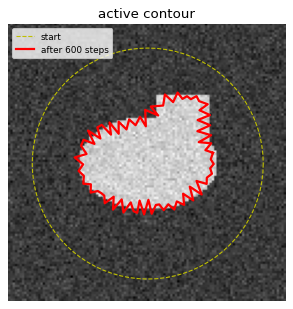

In [5]:
H = W = 120
yy, xx = np.mgrid[:H, :W]
shape = ((xx - 60) ** 2 / 30 ** 2 + (yy - 60) ** 2 / 20 ** 2 < 1) | ((np.abs(xx - 75) < 12) & (np.abs(yy - 45) < 15))
img = shape.astype(float) + rng.normal(0, 0.1, shape.shape)
k = np.exp(-np.arange(-6, 7) ** 2 / 8); k /= k.sum()
sm = np.apply_along_axis(lambda r: np.convolve(r, k, "same"), 0, np.apply_along_axis(lambda r: np.convolve(r, k, "same"), 1, img))
gy, gx = np.gradient(sm); edge = np.hypot(gx, gy)
ey, ex = np.gradient(edge)                            # the snake climbs the edge-strength map

def sample(f, p):
    x, y = p[:, 0].clip(0, W - 1.001), p[:, 1].clip(0, H - 1.001)
    x0, y0 = x.astype(int), y.astype(int); dx, dy = x - x0, y - y0
    return f[y0, x0] * (1 - dx) * (1 - dy) + f[y0, x0 + 1] * dx * (1 - dy) + f[y0 + 1, x0] * (1 - dx) * dy + f[y0 + 1, x0 + 1] * dx * dy

N = 80; a = np.linspace(0, 2 * np.pi, N, endpoint=False)
v = np.c_[60 + 50 * np.cos(a), 60 + 50 * np.sin(a)]
start = v.copy()
alpha, beta, gamma, balloon = 0.3, 0.02, 40.0, 0.4
for it in range(600):
    d2 = np.roll(v, -1, 0) - 2 * v + np.roll(v, 1, 0)                    # elasticity (one neighbour each side)
    d4 = np.roll(d2, -1, 0) - 2 * d2 + np.roll(d2, 1, 0)                 # smoothness (two neighbours each side)
    img_force = np.c_[sample(ex, v), sample(ey, v)]
    tangent = np.roll(v, -1, 0) - np.roll(v, 1, 0)
    normal_in = np.c_[-tangent[:, 1], tangent[:, 0]]; normal_in /= np.linalg.norm(normal_in, axis=1, keepdims=True) + 1e-9
    weak = (sample(edge, v) < 0.5 * edge.max())[:, None]                 # push inward only away from edges
    v = v + alpha * d2 - beta * d4 + gamma * img_force + balloon * weak * normal_in
plt.figure(figsize=(4.5, 4.5)); plt.imshow(img, cmap="gray")
plt.plot(*np.r_[start, start[:1]].T, "y--", lw=1, label="start")
plt.plot(*np.r_[v, v[:1]].T, "r", lw=2, label="after 600 steps")
plt.legend(fontsize=8, loc="upper left"); plt.axis("off"); plt.title("active contour"); plt.show()